## 1. Busniness Understanding

- Identify natural groupings of colleges based on performance and infrastructure metrics
- Avoid human bias in classification
- Build a data-driven segmentation system

## 2. Data Collection

#### 2.1 Import necessary library and datasets

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering

college_data = pd.read_csv("college_list.csv")
college_data.head()

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9


## 3. Data Understanding

In [2]:
college_data.shape

(500, 6)

In [3]:
college_data.isna().sum()

College_Name             0
Student_Faculty_Ratio    0
Annual_Fees_INR          0
Placement_Percentage     0
Average_Package_LPA      0
Infrastructure_Score     0
dtype: int64

In [4]:
college_data.duplicated().unique()

array([False])

In [5]:
college_data.describe()

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
count,500.000000,500.000000,500.000000,500.000000,500.00000
mean,18.084000,138763.710000,69.000000,6.991720,5.97600
std,6.683283,63928.678815,17.193465,2.917991,2.00486
min,8.000000,30404.000000,40.000000,2.000000,3.00000
25%,12.000000,82610.500000,53.750000,4.472500,4.00000
50%,18.000000,140290.500000,69.000000,7.155000,6.00000
75%,24.000000,193422.000000,84.000000,9.432500,8.00000
max,29.000000,249930.000000,99.000000,11.990000,9.00000


## 4. Data Preparation

#### 4.1 Data Cleaning 

In [6]:
X = college_data.drop("College_Name",axis = 1)# college name is not a required feature 
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,14,113042,59,9.20,8
1,27,115999,67,3.07,7
2,22,47955,50,3.40,9
3,18,67841,43,4.64,8
4,15,100640,54,4.66,9
...,...,...,...,...,...
495,17,106323,56,9.33,5
496,12,39111,76,3.62,7
497,16,199182,64,3.88,3
498,10,46389,77,9.31,6


#### 4.2 Data Transformation

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled,columns= X.columns)

In [8]:
X_scaled

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,-0.611689,-0.402753,-0.582199,0.757539,1.010558
1,1.335411,-0.356452,-0.116440,-1.345326,0.511270
2,0.586526,-1.421892,-1.106178,-1.232121,1.509845
3,-0.012581,-1.110515,-1.513717,-0.806745,1.010558
4,-0.461912,-0.596945,-0.873298,-0.799884,1.509845
...,...,...,...,...,...
495,-0.162358,-0.507960,-0.756858,0.802135,-0.487305
496,-0.911243,-1.560372,0.407539,-1.156651,0.511270
497,-0.312135,0.946035,-0.291099,-1.067459,-1.485880
498,-1.210797,-1.446412,0.465759,0.795274,0.011983


## 5. Model Building 

#### Step 1 Check the dendogram 

Text(0, 0.5, 'Euclidean Distance')

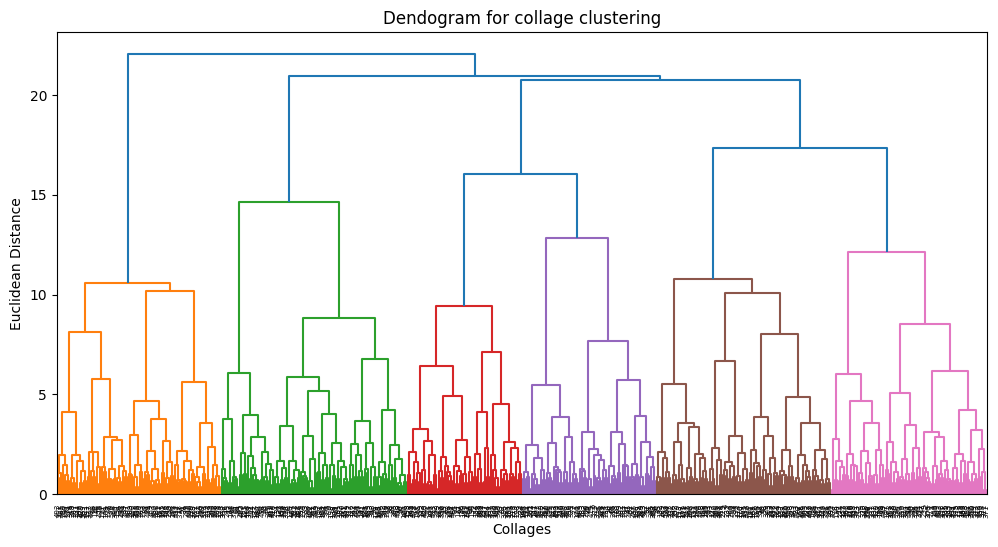

In [9]:
plt.figure(figsize = (12,6))
sch.dendrogram(sch.linkage(X_scaled, method='ward'))
plt.title("Dendogram for collage clustering")
plt.xlabel("Collages")
plt.ylabel("Euclidean Distance")

#### For understanding purpose just take 25 data only

Text(0, 0.5, 'Euclidean Distance')

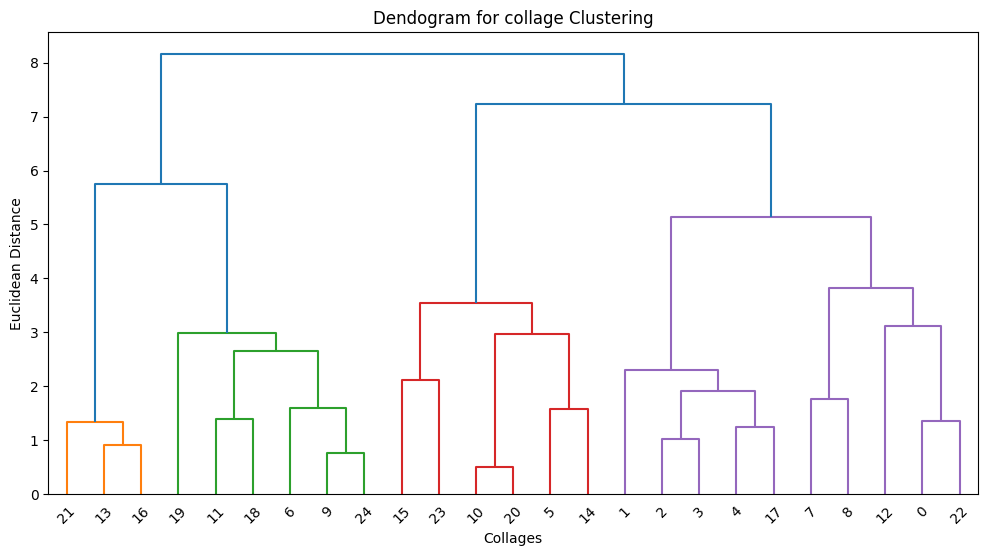

In [10]:
plt.figure(figsize = (12,6))
sch.dendrogram(sch.linkage(X_scaled.head(25), method='ward'))
plt.title("Dendogram for collage Clustering")
plt.xlabel("Collages")
plt.ylabel("Euclidean Distance")

In [11]:
hc_model = AgglomerativeClustering(n_clusters=3)
hc_model.fit_predict(X_scaled)

array([2, 0, 0, 0, 0, 0, 1, 0, 2, 1, 0, 1, 0, 2, 0, 0, 2, 0, 1, 1, 0, 2,
       2, 0, 1, 0, 0, 0, 0, 0, 0, 2, 1, 2, 2, 0, 1, 0, 2, 1, 0, 1, 0, 0,
       2, 0, 1, 0, 0, 0, 0, 1, 0, 2, 0, 0, 2, 0, 0, 2, 2, 2, 0, 0, 2, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 2, 1, 0, 2,
       0, 2, 2, 2, 0, 0, 0, 0, 0, 2, 1, 2, 2, 1, 0, 0, 2, 2, 0, 1, 1, 2,
       0, 2, 1, 0, 0, 0, 0, 1, 2, 0, 0, 0, 2, 2, 0, 0, 2, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 2, 2, 2, 2, 0, 0, 2, 0, 1, 0, 0, 2, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 2, 1, 0, 2, 1, 0, 0, 0, 0,
       2, 0, 0, 1, 1, 2, 0, 2, 1, 0, 1, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 2, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 2, 2,
       0, 0, 2, 2, 1, 0, 0, 0, 1, 0, 1, 0, 0, 2, 0, 1, 1, 1, 0, 2, 0, 0,
       1, 0, 0, 1, 0, 0, 2, 1, 0, 1, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 2, 0, 0, 1, 0, 0, 0, 2, 0, 1, 0, 0, 1, 0,

### Step 2 Attach clusters to dataset and Categorize the clusters based on requirement

#### 1. Attach clusters to dataset

In [12]:
college_data["College_Level"] = hc_model.fit_predict(X_scaled)
college_data.head()

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College_Level
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8,2
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7,0
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9,0
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8,0
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9,0


In [13]:
#we need to use X becoz College data have catergerical data(Dataname) with that we can't catergorize so better agg with numerical fetures
X["College_Level"] = hc_model.fit_predict(X_scaled)
X.head()

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College_Level
0,14,113042,59,9.20,8,2
1,27,115999,67,3.07,7,0
2,22,47955,50,3.40,9,0
3,18,67841,43,4.64,8,0
4,15,100640,54,4.66,9,0


#### 2. Analyse Cluster and categorize - Data mining 

In [15]:
X.groupby(by = "College_Level").agg(["mean"]);

In [16]:
X.groupby(by = "College_Level").agg(["min","max"])

Student_Faculty_Ratio     Annual_Fees_INR          \
                                min max             min     max   
College_Level                                                     
0                                 8  29           30404  249536   
1                                 8  29           39337  248803   
2                                 8  20           49065  249930   

              Placement_Percentage     Average_Package_LPA         \
                               min max                 min    max   
College_Level                                                       
0                               40  99                2.00  11.99   
1                               64  99                2.09  11.96   
2                               40  99                2.01  11.91   

              Infrastructure_Score      
                               min max  
College_Level                           
0                                3   9  
1                                3   9  
2                                3   9

In [17]:
cluster_names = {1:"Best Collages",
                2:"Mid-Level Collages",
                0:"Emerging Collages"
               }
X["Category"] = X["College_Level"].map(cluster_names)
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College_Level,Category
0,14,113042,59,9.20,8,2,Mid-Level Collages
1,27,115999,67,3.07,7,0,Emerging Collages
2,22,47955,50,3.40,9,0,Emerging Collages
3,18,67841,43,4.64,8,0,Emerging Collages
4,15,100640,54,4.66,9,0,Emerging Collages
...,...,...,...,...,...,...,...
495,17,106323,56,9.33,5,0,Emerging Collages
496,12,39111,76,3.62,7,0,Emerging Collages
497,16,199182,64,3.88,3,1,Best Collages
498,10,46389,77,9.31,6,0,Emerging Collages


#### Step 3 Transition to supervised learning

In [18]:
X_input = X.drop(["College_Level","Category"],axis = 1)
y = X["College_Level"]

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report

X_train, X_test, y_train, y_test  = train_test_split(X_input,y,test_size=.2,random_state=39,shuffle=True,stratify=y)


rf_classifier = RandomForestClassifier(n_estimators=50)
rf_classifier.fit(X_train, y_train)

,n_estimators,50
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [20]:
y_pred_train = rf_classifier.predict(X_train)
y_pred_test = rf_classifier.predict(X_test)


print("Train Accuracy Score",accuracy_score(y_train,y_pred_train))
print("Test Accuracy Score",accuracy_score(y_test,y_pred_test))

print("Train Classification report \n",classification_report(y_train,y_pred_train))
print("Test Classification report \n",classification_report(y_test,y_pred_test))

Train Accuracy Score 1.0
Test Accuracy Score 0.94
Train Classification report 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       250
           1       1.00      1.00      1.00        70
           2       1.00      1.00      1.00        80

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400

Test Classification report 
               precision    recall  f1-score   support

           0       0.95      0.95      0.95        62
           1       0.90      1.00      0.95        18
           2       0.94      0.85      0.89        20

    accuracy                           0.94       100
   macro avg       0.93      0.93      0.93       100
weighted avg       0.94      0.94      0.94       100

